# Лабораторная 1: предобработка и EDA датасета отзывов «Перекрёсток»

Датасет: [`lapki/perekrestok-reviews`](https://huggingface.co/datasets/lapki/perekrestok-reviews) — ~642k русскоязычных отзывов о товарах.


## Установка зависимостей (запустить при необходимости)

In [43]:
%pip install datasets pandas numpy matplotlib seaborn pymorphy3 nltk emoji num2words -q


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip3.12 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42

# 1. Загрузка и знакомство с данными


In [46]:
df = pd.read_json("hf://datasets/lapki/perekrestok-reviews/perekrestok.jsonl", lines=True)

df.head()

,product_id,product_name,product_category,product_price,review_id,review_author,review_text,rating
0,1261049,Десерт Fit Kit глазированный протеиновый Двойной шоколад 70г,Здоровое питание,213.0,3396923,Милана,"Самое вкусное протеиновое печенье с белковым суфле из всех, что есть на рынке на данный момент. ...",5.0
1,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1977331,любовь,"Веселая свечка, но нам пришла розовая, как на фото) буду искать дальше нейтрального цвета единичку.",5.0
2,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1451326,инна,Хорошая яркая свечка,5.0
3,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,449473,Marina,"Ребенок в восторге от свечек! Она красная, кстати, не розовая. Что круто!",5.0
4,1271460,Сибас филе охлажденное,"Рыба, икра",1779.0,3444792,Роман,"Хорошая рыба, вкусная, свежая. Жаль, что возят без охлаждающего льда.",5.0


Размерность, признаки и их типы.

In [47]:
print("Количество объектов (строк):", df.shape[0])
print("Количество признаков (столбцов):", df.shape[1])
print()
df.info()

Количество объектов (строк): 642682
Количество признаков (столбцов): 8

<class 'pandas.DataFrame'>
RangeIndex: 642682 entries, 0 to 642681
Data columns (total 8 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   product_id        642682 non-null  int64  
 1   product_name      642682 non-null  str    
 2   product_category  642682 non-null  str    
 3   product_price     642682 non-null  float64
 4   review_id         642682 non-null  int64  
 5   review_author     642682 non-null  str    
 6   review_text       642682 non-null  str    
 7   rating            642682 non-null  float64
dtypes: float64(2), int64(2), str(4)
memory usage: 211.5 MB


Разделим признаки по типам вручную (на основе смысла и dtypes):

- **Числовые**: `product_price`, `rating`
- **Категориальные**: `product_category`
- **Текстовые**: `review_text`, `review_author`, `product_name`
- **Идентификаторы**: `review_id`, `product_id` (служебные, не признаки для модели)


In [48]:
numeric_cols = ["product_price", "rating"]
categorical_cols = ["product_category", "product_name", "review_author"]
text_cols = ["review_text"]
id_cols = ["product_id", "review_id"]

# 2. Статистический анализ

## Числовые признаки
Количество, среднее, медиана, мода, дисперсия, std, min, max, квантили.


In [49]:
stats = df[numeric_cols].describe().T
stats["median"] = df[numeric_cols].median()
stats["mode"] = [df[c].mode().iloc[0] if not df[c].mode().empty else np.nan for c in numeric_cols]
stats["var"] = df[numeric_cols].var()
stats

,count,mean,std,min,25%,50%,75%,max,median,mode,var
product_price,642682.0,271.719698,435.939977,2.9,84.99,149.0,279.9,28220.0,149.0,69.9,190043.663317
rating,642682.0,4.636653,0.840948,0.0,5.00,5.0,5.0,5.0,5.0,5.0,0.707194


## Категориальные и текстовые признаки
Число уникальных значений, частоты, мода.


In [50]:
for c in categorical_cols:
    print(f"=== {c} ===")
    print("Уникальных значений:", df[c].nunique())
    print("Мода:", df[c].mode().iloc[0] if not df[c].mode().empty else "—")
    print("Топ-10 частот:")
    print(df[c].value_counts().head(10))
    print()

=== product_category ===
Уникальных значений: 21
Мода: Овощи, фрукты, ягоды
Топ-10 частот:
product_category
Овощи, фрукты, ягоды       72262
Макароны, крупы, специи    58791
Молоко, сыр, яйца          57980
Сладости                   54101
Мясо, птица, колбасы       45284
Соусы и консервация        42746
Для мам и детей            40948
Воды, соки, напитки        39941
Красота и здоровье         39882
Бытовая химия и гигиена    33616
Name: count, dtype: int64

=== product_name ===
Уникальных значений: 26499
Мода: Лук репчатый 0.4-0.7кг
Топ-10 частот:
product_name
Лук репчатый 0.4-0.7кг             3646
Мандарины 0.8-1.1кг                2673
Яблоки сезонные 0.8-1.1кг          2581
Морковь отечественная              2383
Морковь мытая 0.8-1.2кг            2087
Свекла 0.5-1.1кг                   1894
Смесь NAN Supreme молочная 400г    1765
Апельсины 0.8-1.2кг                1729
Картофель белый мытый 0.8-1.2кг    1720
Смесь NAN Supreme молочная 800г    1712
Name: count, dtype: int64

===

# 3. Анализ текста

Длина отзывов в символах и словах, доля пустых и слишком коротких, самые частые слова после базовой очистки.


In [51]:
df["n_chars"] = df["review_text"].fillna("").astype(str).str.len()
df["n_words"] = df["review_text"].fillna("").astype(str).str.split().apply(len)

print("Длина в символах:")
print(df["n_chars"].describe())
print("\nДлина в словах:")
print(df["n_words"].describe())

Длина в символах:
count    642682.000000
mean         87.331413
std         110.287199
min           0.000000
25%          26.000000
50%          54.000000
75%         105.000000
max        5487.000000
Name: n_chars, dtype: float64

Длина в словах:
count    642682.000000
mean         12.665527
std          16.451121
min           0.000000
25%           4.000000
50%           8.000000
75%          15.000000
max         734.000000
Name: n_words, dtype: float64


In [52]:
n_total = len(df)
n_empty = (df["review_text"].isna() | (df["review_text"].astype(str).str.strip() == "")).sum()
n_short = (df["n_words"] < 3).sum()   # «слишком короткие» — менее 3 слов

print(f"Всего отзывов: {n_total}")
print(f"Пустых отзывов: {n_empty} ({n_empty/n_total:.2%})")
print(f"Коротких (<3 слов): {n_short} ({n_short/n_total:.2%})")

Всего отзывов: 642682
Пустых отзывов: 1 (0.00%)
Коротких (<3 слов): 100699 (15.67%)


## Полная предобработка текста (по шагам, как в лекции-эталоне)

Конвейер применяем к `review_text`:
1. **Regex-очистка**: нижний регистр, удаление ссылок и эмодзи, **перевод чисел в слова** (`num2words`), удаление прочей пунктуации. **Латиницу оставляем** — в отзывах это бренды (`fairy`, `activia`).
2. **Токенизация** (`word_tokenize`).
3. **Удаление пунктуации** (`string.punctuation`).
4. **Удаление стоп-слов** (`stopwords('russian')`) — для EDA берём полный список (отрицания тоже убираем).
5. **Лемматизация** (`pymorphy3`) — приведение к начальной форме.

Сначала разберём каждый шаг на одном отзыве, затем применим ко всей колонке.

In [55]:
from string import punctuation

import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

from pymorphy3 import MorphAnalyzer

import emoji
from num2words import num2words
from tqdm.auto import tqdm
tqdm.pandas()

morph = MorphAnalyzer()
punctuations = set(punctuation)

# EDA: используем полный список стоп-слов (отрицания тоже убираем — в частотном
# анализе они неинформативны). Для задачи сентимента их стоило бы сохранить.
ru_stop = set(stopwords.words("russian")) 

def lemmatize_word(w):
    return morph.parse(w)[0].normal_form

def _num_to_words(match):
    num = match.group()
    # очень длинные цепочки цифр (телефоны, штрихкоды, мусор)
    if len(num) > 9:
        return " "
    try:
        return " " + num2words(int(num), lang="ru") + " "
    except Exception:
        return " "

def regex_clean(text):
    t = str(text)
    t = re.sub(r"_x[0-9a-fA-F]{4}_", " ", t)   # артефакты Excel/OOXML: _x000D_ (\r), _x000A_ (\n), _x0009_ (tab)
    t = t.lower().replace("ё", "е")
    t = re.sub(r"https?://\S+", " ", t)      # ссылки
    t = emoji.replace_emoji(t, replace=" ")   # эмодзи
    t = re.sub(r"\d+", _num_to_words, t)     # числа -> слова (num2words)
    t = re.sub(r"[^a-zа-я\s]", " ", t)       # оставляем кириллицу + латиницу (бренды)
    t = re.sub(r"\s+", " ", t).strip()       # двойные пробелы
    return t

### Диагностика: сколько в текстах чисел и латиницы?

Прежде чем решать, переводить ли числа в слова и оставлять ли латиницу, измерим их реальную долю.
Токенизируем **сырой** текст и снимаем пунктуацию (как в лекции), но пока ничего не удаляем и не нормализуем.

In [56]:
# мини токенизация сырого текста: нижний регистр -> word_tokenize -> без пунктуации
def light_tokens(text):
    toks = word_tokenize(str(text).lower())
    return [t for t in toks if t not in punctuations]

sample_diag = df["review_text"].dropna()

has_digit = re.compile(r"\d")
has_latin = re.compile(r"[a-zA-Z]")

total_tokens = 0
num_tokens = 0        
pure_num_tokens = 0     
latin_tokens = 0
rev_with_num = 0
rev_with_latin = 0

from collections import Counter
latin_counter = Counter()
num_counter = Counter()

for txt in sample_diag:
    toks = light_tokens(txt)
    total_tokens += len(toks)
    r_num = r_lat = False
    for t in toks:
        if has_digit.search(t):
            num_tokens += 1; r_num = True; num_counter[t]+=1
            if t.isdigit(): pure_num_tokens += 1
        if has_latin.search(t):
            latin_tokens += 1; r_lat = True; latin_counter[t]+=1
    rev_with_num += r_num
    rev_with_latin += r_lat

n_rev = len(sample_diag)
print(f"Отзывов проанализировано: {n_rev}")
print(f"Всего токенов: {total_tokens}\n")
print(f"Токенов с цифрами: {num_tokens} ({num_tokens/total_tokens:.3%} от всех токенов)")
print(f"  из них чисто числовых: {pure_num_tokens}")
print(f"Отзывов, где есть хотя бы одно число: {rev_with_num} ({rev_with_num/n_rev:.2%})\n")
print(f"Латинских токенов: {latin_tokens} ({latin_tokens/total_tokens:.3%} от всех токенов)")
print(f"Отзывов, где есть латиница: {rev_with_latin} ({rev_with_latin/n_rev:.2%})")

Отзывов проанализировано: 642682
Всего токенов: 8177182

Токенов с цифрами: 74923 (0.916% от всех токенов)
  из них чисто числовых: 46923
Отзывов, где есть хотя бы одно число: 49880 (7.76%)

Латинских токенов: 30711 (0.376% от всех токенов)
Отзывов, где есть латиница: 14836 (2.31%)


In [57]:
print("Топ-20 латинских токенов (бренды?):")
for w, c in latin_counter.most_common(20):
    print(f"  {w:20s} {c}")

print("\nТоп-20 токенов с цифрами:")
for w, c in num_counter.most_common(20):
    print(f"  {w:20s} {c}")

Топ-20 латинских токенов (бренды?):
  pampers              1504
  pgbonus              1358
  premium              1066
  care                 1006
  fairy                880
  _x000d_              744
  nan                  538
  tide                 535
  gerber               490
  ariel                454
  clean                350
  pure                 343
  d                    332
  color                275
  pods                 257
  gillette             248
  optipro              241
  always               233
  pgбонус              196
  nestle               163

Топ-20 токенов с цифрами:
  2                    6110
  3                    4241
  5                    4179
  1                    4016
  4                    3480
  10                   2465
  100                  2102
  6                    1261
  20                   931
  8                    917
  30                   821
  15                   782
  _x000d_              744
  12                   732
  50   

In [13]:
sample = df["review_text"].dropna().iloc[0]
print("0. Исходный текст:\n", sample, "\n")

cleaned = regex_clean(sample)
print("1. После regex-очистки:\n", cleaned, "\n")

tokens = word_tokenize(cleaned)
print("2. Токенизация:\n", tokens, "\n")

tokens = [t for t in tokens if t not in punctuations]
print("3. Без пунктуации:\n", tokens, "\n")

tokens = [t.lower() for t in tokens]  

no_stop = [t for t in tokens if t not in ru_stop]
print("4. Без стоп-слов:\n", no_stop, "\n")

lemmas = [lemmatize_word(t) for t in no_stop]
print("5. Лемматизация:\n", lemmas)

0. Исходный текст:
 Самое вкусное протеиновое печенье с белковым суфле из всех, что есть на рынке на данный момент. Без неприятного протеинового привкуса, присущего подобного рода изделиям 

1. После regex-очистки:
 самое вкусное протеиновое печенье с белковым суфле из всех что есть на рынке на данный момент без неприятного протеинового привкуса присущего подобного рода изделиям 

2. Токенизация:
 ['самое', 'вкусное', 'протеиновое', 'печенье', 'с', 'белковым', 'суфле', 'из', 'всех', 'что', 'есть', 'на', 'рынке', 'на', 'данный', 'момент', 'без', 'неприятного', 'протеинового', 'привкуса', 'присущего', 'подобного', 'рода', 'изделиям'] 

3. Без пунктуации:
 ['самое', 'вкусное', 'протеиновое', 'печенье', 'с', 'белковым', 'суфле', 'из', 'всех', 'что', 'есть', 'на', 'рынке', 'на', 'данный', 'момент', 'без', 'неприятного', 'протеинового', 'привкуса', 'присущего', 'подобного', 'рода', 'изделиям'] 

4. Без стоп-слов:
 ['самое', 'вкусное', 'протеиновое', 'печенье', 'белковым', 'суфле', 'рынке', '

In [58]:
def preprocess(text):
    tokens = word_tokenize(regex_clean(text))
    tokens = [t for t in tokens if t not in punctuations and t not in ru_stop and len(t) > 1]
    return [lemmatize_word(t) for t in tokens]

df["tokens_lemmas"] = df["review_text"].progress_apply(preprocess)

df["preprocessed"] = df["tokens_lemmas"].apply(" ".join)

df[["review_text", "tokens_lemmas", "preprocessed"]].head()

  0%|          | 0/642682 [00:00<?, ?it/s]

,review_text,tokens_lemmas,preprocessed
0,"Самое вкусное протеиновое печенье с белковым суфле из всех, что есть на рынке на данный момент. ...","[самый, вкусный, протеиновый, печение, белков, суфле, рынок, данный, момент, неприятный, протеин...",самый вкусный протеиновый печение белков суфле рынок данный момент неприятный протеиновый привку...
1,"Веселая свечка, но нам пришла розовая, как на фото) буду искать дальше нейтрального цвета единичку.","[весёлый, свечка, мы, прийти, розовый, фото, быть, искать, далёкий, нейтральный, цвет, единичка]",весёлый свечка мы прийти розовый фото быть искать далёкий нейтральный цвет единичка
2,Хорошая яркая свечка,"[хороший, яркий, свечка]",хороший яркий свечка
3,"Ребенок в восторге от свечек! Она красная, кстати, не розовая. Что круто!","[ребёнок, восторг, свечка, красный, кстати, розовый, круто]",ребёнок восторг свечка красный кстати розовый круто
4,"Хорошая рыба, вкусная, свежая. Жаль, что возят без охлаждающего льда.","[хороший, рыба, вкусный, свежий, жаль, возить, охлаждать, лёд]",хороший рыба вкусный свежий жаль возить охлаждать лёд


In [60]:
# Топ-30 самых частых слов после полной предобработки (по леммам)
counter = Counter()
for toks in df["tokens_lemmas"]:
    counter.update(toks)

print("Топ-30 слов (леммы):")
for w, c in counter.most_common(200):
    print(f"{w:15s} {c}")

Топ-30 слов (леммы):
вкусный         173944
очень           172719
хороший         126622
достоинство     115054
вкус            85481
недостаток      74837
отличный        65667
цена            44110
брать           43582
это             39326
вкусно          38541
понравиться     35239
приятный        33385
нравиться       32566
свежий          31877
запах           31686
качество        31183
смесь           30488
ребёнок         30359
покупать        28988
самый           28383
рекомендовать   27052
состав          26431
упаковка        23152
сладкий         22621
вода            20901
просто          20494
мягкий          20019
такой           18411
отлично         17149
весь            16673
молоко          16476
масло           16429
нежный          16417
сыр             16258
продукт         15572
быстро          15292
один            14882
любить          14722
удобный         14632
быть            13570
аромат          13559
спасибо         13501
чай             13390
пять   

In [65]:
dct = [x[0] for x in counter.most_common(200)]

In [66]:
dct

['вкусный',
 'очень',
 'хороший',
 'достоинство',
 'вкус',
 'недостаток',
 'отличный',
 'цена',
 'брать',
 'это',
 'вкусно',
 'понравиться',
 'приятный',
 'нравиться',
 'свежий',
 'запах',
 'качество',
 'смесь',
 'ребёнок',
 'покупать',
 'самый',
 'рекомендовать',
 'состав',
 'упаковка',
 'сладкий',
 'вода',
 'просто',
 'мягкий',
 'такой',
 'отлично',
 'весь',
 'молоко',
 'масло',
 'нежный',
 'сыр',
 'продукт',
 'быстро',
 'один',
 'любить',
 'удобный',
 'быть',
 'аромат',
 'спасибо',
 'чай',
 'пять',
 'кожа',
 'сочный',
 'мясо',
 'есть',
 'нормальный',
 'который',
 'первый',
 'любимый',
 'другой',
 'купить',
 'мой',
 'маленький',
 'натуральный',
 'крупный',
 'супер',
 'кофе',
 'удобно',
 'стать',
 'день',
 'средство',
 'советовать',
 'пользоваться',
 'качественный',
 'акция',
 'пахнуть',
 'свой',
 'сахар',
 'мера',
 'чистый',
 'год',
 'время',
 'шоколад',
 'пить',
 'подходить',
 'сок',
 'удовольствие',
 'довольный',
 'волос',
 'мало',
 'сам',
 'немного',
 'производитель',
 'размер',
 

# 4. Визуальный анализ

6 графиков с краткими выводами.


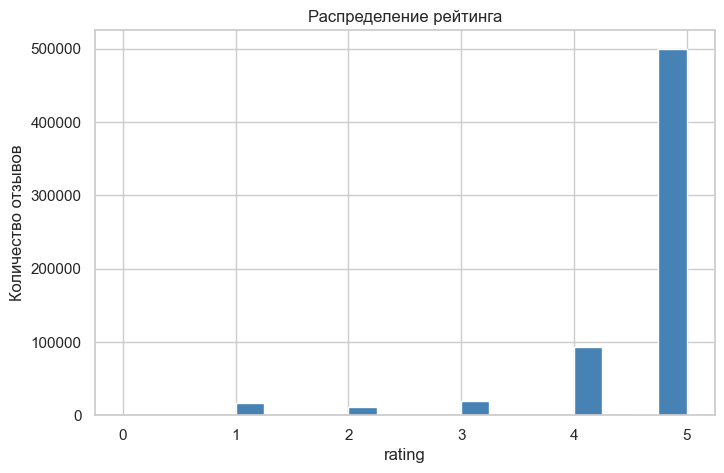

In [16]:
# 1. Распределение рейтинга
plt.figure(figsize=(8, 5))
df["rating"].dropna().plot(kind="hist", bins=20, color="steelblue", edgecolor="white")
plt.title("Распределение рейтинга")
plt.xlabel("rating"); plt.ylabel("Количество отзывов")
plt.show()

Можно сказать, что пользователи в основном отставляют положительные отзывы на товары

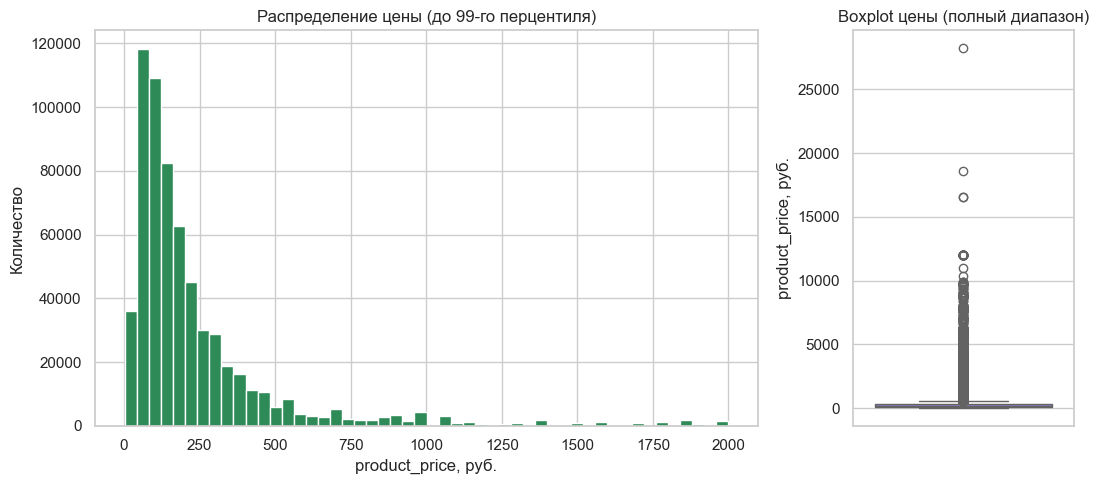

In [17]:
# 2. Распределение цены
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(11, 5),
                                      gridspec_kw={"width_ratios": (3, 1)})

price_cap = df["product_price"].quantile(0.99)

# гистограмма с обрезкой по 99-му перцентилю для читаемости
ax_hist.hist(df.loc[df["product_price"] <= price_cap, "product_price"],
             bins=50, color="seagreen", edgecolor="white")
ax_hist.set_title("Распределение цены (до 99-го перцентиля)")
ax_hist.set_xlabel("product_price, руб.")
ax_hist.set_ylabel("Количество")

# boxplot без обрезки, чтобы видеть крайние значения
sns.boxplot(y=df["product_price"].dropna(), ax=ax_box, color="mediumpurple")
ax_box.set_title("Boxplot цены (полный диапазон)")
ax_box.set_ylabel("product_price, руб.")

plt.tight_layout()
plt.show()

In [18]:
price = df["product_price"].dropna()
for thr in [250, 500, 1000]:
    print(f"до {thr} руб.: {(price < thr).mean():.1%}")
print("медиана:", price.median(), "| мода:", price.mode().iloc[0])
print("95-й перцентиль:", price.quantile(0.95), "| максимум:", price.max())
print("перекос:", round(price.skew(), 2))

до 250 руб.: 71.7%
до 500 руб.: 89.2%
до 1000 руб.: 95.9%
медиана: 149.0 | мода: 69.9
95-й перцентиль: 918.0 | максимум: 28220.0
перекос: 7.46


Распределение цены сильно скошено вправо (skew ≈ 7.46). 71.7 % отзывов приходится на товары дешевле 250 руб., 89.2 % - дешевле 500 руб. и 95.9 % - дешевле 1000 руб. То есть покупатели комментируют в основном повседневные дешёвые продукты. Правый хвост длинный и разреженный: 95-й перцентиль - всего 918 руб., но встречаются единичные дорогие позиции вплоть до 28 220 руб. (много выбросов высоко над верхним усом). Из-за такого перекоса «типичную» цену корректнее оценивать по медиане, она составляет 149 руб.

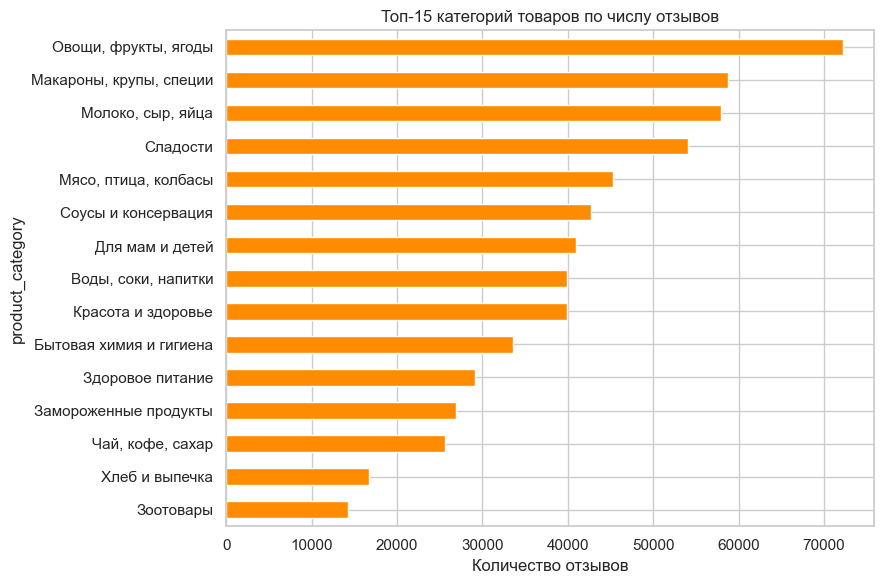

In [19]:
# 3. Частоты категорий товаров
plt.figure(figsize=(9, 6))
df["product_category"].value_counts().head(15).sort_values().plot(
    kind="barh", color="darkorange")
plt.title("Топ-15 категорий товаров по числу отзывов")
plt.xlabel("Количество отзывов")
plt.tight_layout()
plt.show()

Довольно базовый набор: первые 5 мест забрали отзывы на продукты первой необходимости.

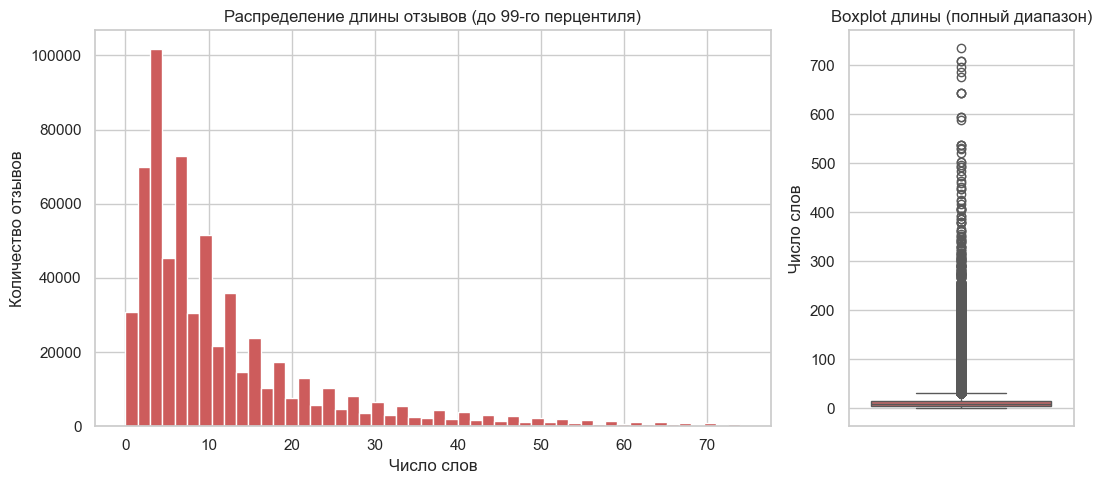

In [20]:
# 3. Распределение длины отзывов
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(11, 5),
                                      gridspec_kw={"width_ratios": (3, 1)})

words_cap = df["n_words"].quantile(0.99)

ax_hist.hist(df.loc[df["n_words"] <= words_cap, "n_words"],
             bins=50, color="indianred", edgecolor="white")
ax_hist.set_title("Распределение длины отзывов (до 99-го перцентиля)")
ax_hist.set_xlabel("Число слов")
ax_hist.set_ylabel("Количество отзывов")

sns.boxplot(y=df["n_words"].dropna(), ax=ax_box, color="indianred")
ax_box.set_title("Boxplot длины (полный диапазон)")
ax_box.set_ylabel("Число слов")

plt.tight_layout()
plt.show()

In [21]:
w = df["n_words"]
for thr in [3, 5, 10, 20]:
    print(f"до {thr} слов: {(w < thr).mean():.1%}")
print("медиана:", w.median(), "| мода:", w.mode().iloc[0])
print("среднее:", round(w.mean(), 1))
print("95-й перцентиль:", w.quantile(0.95), "| максимум:", w.max())
print("перекос:", round(w.skew(), 2))
print("очень короткие (<3 слов):", f"{(w < 3).mean():.1%}")

до 3 слов: 15.7%
до 5 слов: 31.5%
до 10 слов: 58.9%
до 20 слов: 81.9%
медиана: 8.0 | мода: 2
среднее: 12.7
95-й перцентиль: 42.0 | максимум: 734
перекос: 6.19
очень короткие (<3 слов): 15.7%


Длина отзывов сильно скошена вправо: медиана 8 слов при среднем 12.7 (из-за длинного хвоста), то есть большинство отзывов короткие. Самая частая длина - 2 слова, а 15.7 % отзывов содержат менее 3 слов (скорее всего короткие оценочные отзывы вроде «отлично», «не понравилось»). Почти треть (31.5 %) укладывается в 5 слов, больше половины (58.9 %) - в 10 слов. При этом есть длинный хвост развёрнутых отзывов: 95-й перцентиль — всего 42 слова, но максимум достигает 734 слов. Для будущего использования можно думать над тем, что очень короткие отзывы стоит либо отфильтровать, либо учитывать их низкую информативность, а саму длину можно рассматривать как дополнительный признак

In [22]:
df.rating.value_counts()

rating
5.0    500198
4.0     93425
3.0     19081
1.0     16563
2.0     10840
4.7       914
4.3       545
3.7       242
3.3       177
2.7       172
2.3       164
1.7       134
1.3        93
4.5        49
0.0        19
1.5        18
3.5        14
2.5        12
4.6         8
4.8         8
0.3         4
4.9         1
0.7         1
Name: count, dtype: int64

In [23]:
r = df["rating"].dropna()

is_int = (r == r.round())
share_int = is_int.mean()
n_frac = (~is_int).sum()
n_frac_unique = r[~is_int].round(1).nunique()

print(f"Доля целочисленных оценок (1–5, 0): {share_int:.2%}")
print(f"Дробных записей всего: {n_frac:,} ({n_frac/len(r):.2%})")
print(f"Уникальных дробных значений: {n_frac_unique}")

print("\nРедкие дробные оценки (n <= 5):")
vc = r.value_counts()
print(vc[vc <= 5].sort_index())

Доля целочисленных оценок (1–5, 0): 99.60%
Дробных записей всего: 2,556 (0.40%)
Уникальных дробных значений: 17

Редкие дробные оценки (n <= 5):
rating
0.3    4
0.7    1
4.9    1
Name: count, dtype: int64


Исходный признак rating принимает дробные значения, но их распределение показывает, что шкала фактически целочисленная: на оценки 1-5 приходится 99.6 % отзывов, тогда как все дробные значения (4.7, 4.3, 3.7 и т. д.) вместе дают лишь ~2.5 тыс. записей, а некоторые встречаются единично (0.7 - 1 отзыв, 4.9 - 1 отзыв). Такие категории статистически неустойчивы (boxplot по ним не даст нам ничего), округлять тоже не станем, этих значений и правда не так много, поэтому для анализа связи длины и оценки ограничимся целыми значениями без потери значимой доли данных

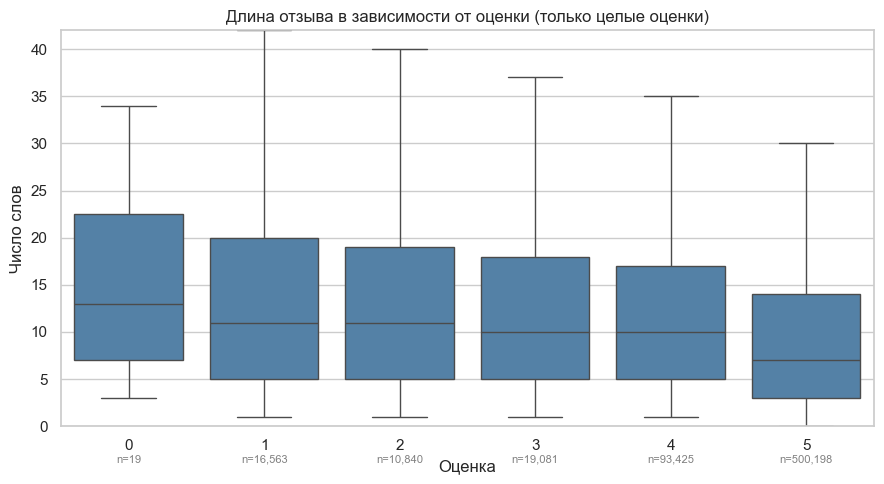

In [24]:
tmp = df.dropna(subset=["rating", "n_words"]).copy()

tmp = tmp[tmp["rating"] == tmp["rating"].round()]
tmp["rating_int"] = tmp["rating"].astype(int)

counts = tmp["rating_int"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
sns.boxplot(data=tmp, x="rating_int", y="n_words", color="steelblue", showfliers=False)
plt.ylim(0, df["n_words"].quantile(0.95))
plt.title("Длина отзыва в зависимости от оценки (только целые оценки)")
plt.xlabel("Оценка"); plt.ylabel("Число слов")

# подпишем число отзывов под каждой оценкой
for i, r in enumerate(sorted(tmp["rating_int"].unique())):
    plt.text(i, -3, f"n={counts[r]:,}", ha="center", va="top", fontsize=8, color="gray")

plt.tight_layout()
plt.show()

Прослеживается обратная связь между оценкой и длиной отзыва: чем выше оценка, тем короче текст. Медианная длина падает с ~13 слов у оценки 0 и ~11 у оценок 1–2 до 7 слов у оценки 5. Видимо довольные покупатели чаще ограничиваются короткой похвалой, тогда как при низких и средних оценках отзывы длиннее и с большим разбросом, возможно, недовольные подробнее описывают, что именно не так. Отдельно видно, что у оценки 5 распределение не только самое низкое по медиане, но и самое плотное (видно по узкой коробке и наиболее короткому усу ), то есть положительные отзывы наиболее однородны по длине. При этом стоит помнить про сильный дисбаланс: оценка 5 опирается на ~500 тыс. отзывов, а оценка 0 - всего на 19, поэтому «коробка» для 0 не совсем статистически ненадёжна

# 5. Проверка качества данных

Пропуски, дубликаты, некорректные значения.


In [25]:
print("Пропуски по столбцам:")
print(df.isna().sum())

base_cols = ["product_id", "product_name", "product_category", "product_price",
             "review_id", "review_author", "review_text", "rating"]
base_cols = [c for c in base_cols if c in df.columns]

print("\nПолные дубликаты строк:", df.duplicated(subset=base_cols).sum())

Пропуски по столбцам:
product_id          0
product_name        0
product_category    0
product_price       0
review_id           0
review_author       0
review_text         0
rating              0
n_chars             0
n_words             0
tokens_lemmas       0
preprocessed        0
dtype: int64

Полные дубликаты строк: 441


Посмотрим на дубли более пристально:

In [26]:
dups = df[df.duplicated(subset=["review_id"], keep=False)].sort_values("review_id")

cols = ["review_id", "product_id", "product_name", "product_category",
        "product_price", "review_author", "review_text", "rating"]
dups[cols].head(20)

,review_id,product_id,product_name,product_category,product_price,review_author,review_text,rating
300605,282634,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Гриша Шариков,Достоинства:\nВкуснейший шоколад\n\nНедостатки...,4.0
300608,282634,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Гриша Шариков,Достоинства:\nВкуснейший шоколад\n\nНедостатки...,4.0
300604,282635,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Алина Пущина,У меня 3 kinder surprise и 3 разных игрушки н...,5.0
300609,282635,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Алина Пущина,У меня 3 kinder surprise и 3 разных игрушки н...,5.0
300610,282636,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Danya Taaaa,Классные подарки и вкусный шоколад,5.0
300603,282636,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Danya Taaaa,Классные подарки и вкусный шоколад,5.0
300602,282637,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Kate Kul,"Очень вкусный шоколад , но игрушки бывают та...",5.0
300611,282637,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Kate Kul,"Очень вкусный шоколад , но игрушки бывают та...",5.0
300601,282638,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Madina Zhantassova,"Шоколад вкусный, игрушка часто не та, которую ...",4.0
300612,282638,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Madina Zhantassova,"Шоколад вкусный, игрушка часто не та, которую ...",4.0


А теперь узнаем, сколько дублей, если мы не берем review_id

In [27]:
key_cols = ["product_id", "product_name", "product_category", "product_price",
            "review_author", "review_text", "rating"]

dup_mask = df.duplicated(subset=key_cols, keep=False)
dups = df[dup_mask].sort_values(key_cols)

print("Строк-дублей по всем полям кроме review_id:", dup_mask.sum())
print("Уникальных комбинаций среди них:", df[dup_mask].drop_duplicates(subset=key_cols).shape[0])

cols = ["review_id"] + key_cols
dups[cols].head(20)

Строк-дублей по всем полям кроме review_id: 24636
Уникальных комбинаций среди них: 9576


,review_id,product_id,product_name,product_category,product_price,review_author,review_text,rating
22654,1952224,303669,Грейпфрут красный 0.9-1.3кг,"Овощи, фрукты, ягоды",174.0,Елена,Отличный,5.0
23013,731663,303669,Грейпфрут красный 0.9-1.3кг,"Овощи, фрукты, ягоды",174.0,Елена,Отличный,5.0
24755,3183258,303670,Киви 0.4-0.6кг,"Овощи, фрукты, ягоды",449.0,Ирина,Вкусные,5.0
24945,1588967,303670,Киви 0.4-0.6кг,"Овощи, фрукты, ягоды",449.0,Ирина,Вкусные,5.0
24709,3271972,303670,Киви 0.4-0.6кг,"Овощи, фрукты, ягоды",449.0,Клиент,"Спелые, сладкие.",5.0
25049,1388532,303670,Киви 0.4-0.6кг,"Овощи, фрукты, ягоды",449.0,Клиент,"Спелые, сладкие.",5.0
173331,1879823,303671,Апельсины 0.8-1.2кг,"Овощи, фрукты, ягоды",169.0,Елена,Отличные апельсины,5.0
173897,1248849,303671,Апельсины 0.8-1.2кг,"Овощи, фрукты, ягоды",169.0,Елена,Отличные апельсины,5.0
173027,3341867,303671,Апельсины 0.8-1.2кг,"Овощи, фрукты, ягоды",169.0,Елена,Сочные и сладкие,5.0
173400,1804939,303671,Апельсины 0.8-1.2кг,"Овощи, фрукты, ягоды",169.0,Елена,Сочные и сладкие,5.0


In [28]:
key_cols = ["product_id", "product_name", "product_category", "product_price",
            "review_author", "review_text", "rating"]
dups = df[df.duplicated(subset=key_cols, keep=False)].copy()
dups["n_words"] = dups["review_text"].astype(str).str.split().str.len()

print("Длина текста (слов) в этих дублях:")
print(dups["n_words"].describe())
print("\nДоля дублей с текстом < 3 слов:", f'{(dups["n_words"] < 3).mean():.1%}')

# примеры длинных дублей (>= 6 слов) — вот это уже наверняка повторная выгрузка
long_dups = dups[dups["n_words"] >= 6].sort_values(key_cols)
print("\nСтрок-дублей с длинным текстом (>=6 слов):", len(long_dups))
long_dups[["review_id"] + key_cols].head(10)

Длина текста (слов) в этих дублях:
count    24636.000000
mean        35.773421
std         24.007601
min          1.000000
25%         19.000000
50%         35.000000
75%         50.000000
max        291.000000
Name: n_words, dtype: float64

Доля дублей с текстом < 3 слов: 11.4%

Строк-дублей с длинным текстом (>=6 слов): 21149


,review_id,product_id,product_name,product_category,product_price,review_author,review_text,rating
204817,79012,303799,Ананас 1.5-2кг,"Овощи, фрукты, ягоды",269.0,Лариса,"вкусный, сочный и сладкий. даю несколько дней ...",5.0
204820,78829,303799,Ананас 1.5-2кг,"Овощи, фрукты, ягоды",269.0,Лариса,"вкусный, сочный и сладкий. даю несколько дней ...",5.0
519941,873720,304203,Прокладки Always Ultra Light Duo 20шт,Красота и здоровье,269.0,viki,"Как всегда прокладки на высоте. Качество, впит...",5.0
519942,881077,304203,Прокладки Always Ultra Light Duo 20шт,Красота и здоровье,269.0,viki,"Как всегда прокладки на высоте. Качество, впит...",5.0
519950,879173,304203,Прокладки Always Ultra Light Duo 20шт,Красота и здоровье,269.0,Виктория,Всегда пользуюсь прокладками Always Ultra Ligh...,5.0
519951,872981,304203,Прокладки Always Ultra Light Duo 20шт,Красота и здоровье,269.0,Виктория,Всегда пользуюсь прокладками Always Ultra Ligh...,5.0
519943,873874,304203,Прокладки Always Ultra Light Duo 20шт,Красота и здоровье,269.0,Элиза,Конечно же защищать меня на протяжении всей но...,5.0
519944,881233,304203,Прокладки Always Ultra Light Duo 20шт,Красота и здоровье,269.0,Элиза,Конечно же защищать меня на протяжении всей но...,5.0
300602,282637,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Kate Kul,"Очень вкусный шоколад , но игрушки бывают та...",5.0
300611,282637,304206,Яйцо Kinder Сюрприз из молочного шоколада с иг...,Сладости,99.9,Kate Kul,"Очень вкусный шоколад , но игрушки бывают та...",5.0


Проверка по всем полям, кроме review_id, выявила 24 636 строк в дублях (15 060 лишних копий). Их тексты развёрнутые (медиана 35 слов), поэтому дословное совпадение вместе с автором, товаром, ценой и рейтингом исключает случайность - это повторные выгрузки одной записи, получившие разные review_id. Следовательно, review_id не является надёжным ключом уникальности, и дедупликацию лучше провести по содержательно-метаданному ключу (с сохранением первой записи), что удаляет ~15 тыс. реальных повторов против 441 при опоре только на review_id.

In [29]:
# некорректные значения
print("Отзывы без текста:", (df["review_text"].isna() | (df["review_text"].astype(str).str.strip()=="")).sum())
print("Цена <= 0 или NaN:", ((df["product_price"] <= 0) | df["product_price"].isna()).sum())
print("Рейтинг вне [0,5]:", ((df["rating"] < 0) | (df["rating"] > 5)).sum())
print("Уникальные категории:", df["product_category"].nunique())

Отзывы без текста: 1
Цена <= 0 или NaN: 0
Рейтинг вне [0,5]: 0
Уникальные категории: 21


### Согласованность метаданных товара (product_id → name / category / price)

Один `product_id` должен стабильно соответствовать одному названию, категории и (в идеале) цене.
Проверим, нет ли конфликтов — это определяет, можно ли считать `product_name` производным от id.

In [30]:
g = df.groupby("product_id").agg(
    n_rows=("review_id", "size"),
    n_names=("product_name", "nunique"),
    n_categories=("product_category", "nunique"),
    n_prices=("product_price", "nunique"),
)

print("Товаров (уникальных product_id):", len(g))
print("id с >1 названием:",  (g["n_names"] > 1).sum())
print("id с >1 категорией:", (g["n_categories"] > 1).sum())
print("id с >1 ценой:",      (g["n_prices"] > 1).sum())

# примеры конфликтов по категории
bad_cat = g[g["n_categories"] > 1].index[:5]
for pid in bad_cat:
    print(f"\nproduct_id={pid}")
    print(df.loc[df["product_id"] == pid, ["product_name", "product_category", "product_price"]]
            .drop_duplicates())

Товаров (уникальных product_id): 26609
id с >1 названием: 0
id с >1 категорией: 0
id с >1 ценой: 0


# 6. Очистка данных

Применяем обоснованную обработку и фиксируем, сколько строк удалено.


In [31]:
before = len(df)
log = {}

# пустые отзывы
mask_empty = df["review_text"].isna() | (df["review_text"].astype(str).str.strip() == "")
df = df[~mask_empty].copy()
log["удалено пустых отзывов"] = int(mask_empty.sum())

# дубликаты по содержанию+метаданным (без review_id)
key_cols = ["product_id", "product_name", "product_category", "product_price",
            "review_author", "review_text", "rating"]
dup_mask = df.duplicated(subset=key_cols)
df = df[~dup_mask].copy()
log["удалено дубликатов (ключ без review_id)"] = int(dup_mask.sum())

# некорректный рейтинг
bad_rating = (df["rating"] < 0) | (df["rating"] > 5) | df["rating"].isna()
df = df[~bad_rating].copy()
log["удалено с некорректным рейтингом"] = int(bad_rating.sum())

# цена <= 0 -> NaN, затем заполнить медианой по категории
df.loc[df["product_price"] <= 0, "product_price"] = np.nan
n_price_na = df["product_price"].isna().sum()
df["product_price"] = df["product_price"].fillna(
    df.groupby("product_category")["product_price"].transform("median"))
df["product_price"] = df["product_price"].fillna(df["product_price"].median())
log["цен заполнено медианой"] = int(n_price_na)

df = df.reset_index(drop=True)
after = len(df)
log["итог: строк было"] = before
log["итог: строк стало"] = after
log["итог: удалено всего"] = before - after
pd.Series(log)

удалено пустых отзывов                          1
удалено дубликатов (ключ без review_id)     15060
удалено с некорректным рейтингом                0
цен заполнено медианой                          0
итог: строк было                           642682
итог: строк стало                          627621
итог: удалено всего                         15061
dtype: int64

In [32]:
# приводим дробные оценки к целым: порог 0.5, ближайшее целое (на .5 — вверх)
df["rating"] = np.floor(df["rating"].astype(float) + 0.5).clip(0, 5).astype(int)
print(df["rating"].value_counts().sort_index())

rating
0        23
1     16651
2     11153
3     19434
4     93928
5    486432
Name: count, dtype: int64


# 7. Поиск выбросов

Ищем выбросы в `product_price` и в длине отзыва методом IQR.


In [34]:
col = "product_price"
cols = ["product_name", "product_category", "product_price", "rating"]

s = df[col].dropna()
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5*iqr, q3 + 1.5*iqr

print(f"Границы IQR: [{low:.2f}, {high:.2f}]")
print(f"Выбросов снизу (< {low:.2f}):", (df[col] < low).sum())
print(f"Выбросов сверху (> {high:.2f}):", (df[col] > high).sum())

print("\n=== 10 самых ДОРОГИХ (верхние выбросы) ===")
display(df.nlargest(10, col)[cols])

print("\n=== 10 самых ДЕШЁВЫХ значений ===")
display(df.nsmallest(10, col)[cols])

Границы IQR: [-191.25, 545.15]
Выбросов снизу (< -191.25): 0
Выбросов сверху (> 545.15): 53463

=== 10 самых ДОРОГИХ (верхние выбросы) ===


,product_name,product_category,product_price,rating
229703,Конструктор LEGO Technic 42129 Полноприводный ...,Для мам и детей,28220.0,5
504970,Бассейн каркасный Intex Metal Frame 366*76см,"Дом, дача, книги",18599.0,4
203335,Конструктор LEGO Ninjago 71756 Подводный Дар С...,Для мам и детей,16532.0,5
203336,Конструктор LEGO Ninjago 71756 Подводный Дар С...,Для мам и детей,16532.0,4
131815,Миксер Kitfort КТ-1348-1 планетарный,Бытовая техника,11990.0,5
131816,Миксер Kitfort КТ-1348-1 планетарный,Бытовая техника,11990.0,4
131817,Миксер Kitfort КТ-1348-1 планетарный,Бытовая техника,11990.0,5
131818,Миксер Kitfort КТ-1348-1 планетарный,Бытовая техника,11990.0,5
131819,Миксер Kitfort КТ-1348-1 планетарный,Бытовая техника,11990.0,5
131820,Миксер Kitfort КТ-1348-1 планетарный,Бытовая техника,11990.0,4



=== 10 самых ДЕШЁВЫХ значений ===


,product_name,product_category,product_price,rating
511209,Ванилин Восточный базар 1.5г,"Макароны, крупы, специи",2.9,5
511210,Ванилин Восточный базар 1.5г,"Макароны, крупы, специи",2.9,5
511211,Ванилин Восточный базар 1.5г,"Макароны, крупы, специи",2.9,5
511212,Ванилин Восточный базар 1.5г,"Макароны, крупы, специи",2.9,1
511213,Ванилин Восточный базар 1.5г,"Макароны, крупы, специи",2.9,3
511214,Ванилин Восточный базар 1.5г,"Макароны, крупы, специи",2.9,5
511215,Ванилин Восточный базар 1.5г,"Макароны, крупы, специи",2.9,5
511216,Ванилин Восточный базар 1.5г,"Макароны, крупы, специи",2.9,5
511217,Ванилин Восточный базар 1.5г,"Макароны, крупы, специи",2.9,5
511218,Ванилин Восточный базар 1.5г,"Макароны, крупы, специи",2.9,5


In [35]:
col = "n_words"
cols = ["review_text", "n_words", "rating", "product_category"]

s = df[col].dropna()
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5*iqr, q3 + 1.5*iqr

print(f"Границы IQR: [{low:.2f}, {high:.2f}]")
print(f"Выбросов снизу (< {low:.2f}):", (df[col] < low).sum())
print(f"Выбросов сверху (> {high:.2f}):", (df[col] > high).sum())

pd.set_option("display.max_colwidth", 100)  # чтобы длинный текст не обрезался в ноль

print("\n=== 10 самых ДЛИННЫХ отзывов (верхние выбросы) ===")
display(df.nlargest(10, col)[cols])

print("\n=== 10 самых КОРОТКИХ отзывов ===")
display(df.nsmallest(10, col)[cols])

Границы IQR: [-11.00, 29.00]
Выбросов снизу (< -11.00): 0
Выбросов сверху (> 29.00): 53732

=== 10 самых ДЛИННЫХ отзывов (верхние выбросы) ===


,review_text,n_words,rating,product_category
427231,Достоинства:\nКачесвотво.\nВкусно.\nДостойные макароны по приемлемой цене.\n\nМакароны: польза и...,734,5,"Макароны, крупы, специи"
240202,Бодрость без страха за фигуру. Сегодня мой отзыв не для ЗОЖников и моралфагов.\nЯ хочу написать ...,709,5,"Воды, соки, напитки"
517866,Бодрость без страха за фигуру. Сегодня мой отзыв не для ЗОЖников и моралфагов.\nЯ хочу написать ...,709,5,"Воды, соки, напитки"
70490,"Достоинства:\nЧистая, белая, с хорошими показателями, без примесей и живности типа долгоносиков ...",696,5,"Макароны, крупы, специи"
329986,ОНА ЛУЧШАЯ!!! Теперь я знаю как помочь волосам когда им плохо!!!\nПеред покупкой этой маски отзы...,686,5,Красота и здоровье
20338,"Крем, который действительно работает. Наконец-то я нашла идеальное средство, которое способно ра...",675,5,Аптечка
124045,Достоинства:\nВкусное\nНикак не могу найти мороженного вообще без Е.\nВ составе мороженного есть...,644,4,Замороженные продукты
240182,Хороший вариант подобного напитка без каких-то либо страхов за свою фигуру...Приветствую всех за...,644,5,"Воды, соки, напитки"
517847,Хороший вариант подобного напитка без каких-то либо страхов за свою фигуру...Приветствую всех за...,644,5,"Воды, соки, напитки"
20337,Натуральный легкий крем для нежной кожи вокруг глаз: незаметно борется с первыми признаками стар...,594,5,Аптечка



=== 10 самых КОРОТКИХ отзывов ===


,review_text,n_words,rating,product_category
89,Акция￼,1,5,Зоотовары
115,Хорошая,1,5,"Мясо, птица, колбасы"
116,Хорошая,1,5,"Мясо, птица, колбасы"
120,Хороший.,1,5,"Воды, соки, напитки"
126,Качество,1,5,"Воды, соки, напитки"
132,Спасибо,1,5,"Воды, соки, напитки"
133,Вкус,1,5,"Воды, соки, напитки"
159,Вкусный,1,5,"Воды, соки, напитки"
230,Качественные,1,5,Красота и здоровье
239,Удобные,1,5,Красота и здоровье


Способ обнаружения — метод межквартильного размаха (IQR). По нему ~8.5 % значений цены и длины попадают в «выбросы» (всё выше верхней границы). Однако это не ошибки, а допустимые наблюдения: реальные дорогие товары и длинные отзывы. Удалять их не нужно.

# 8. Разделение данных

Train / Validation / Test

In [38]:
from sklearn.model_selection import train_test_split

# 70 / 15 / 15, стратификация по оценке
train_df, tmp_df = train_test_split(
    df, test_size=0.30, random_state=RANDOM_STATE, stratify=df["rating"])
val_df, test_df = train_test_split(
    tmp_df, test_size=0.50, random_state=RANDOM_STATE, stratify=tmp_df["rating"])

print("train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))

# доли оценок по выборкам — должны совпадать
dist = pd.DataFrame({
    "train": train_df["rating"].value_counts(normalize=True),
    "val":   val_df["rating"].value_counts(normalize=True),
    "test":  test_df["rating"].value_counts(normalize=True),
}).sort_index().round(3)
print(dist)

train: 439334 | val: 94143 | test: 94144
        train    val   test
rating                     
0       0.000  0.000  0.000
1       0.027  0.027  0.027
2       0.018  0.018  0.018
3       0.031  0.031  0.031
4       0.150  0.150  0.150
5       0.775  0.775  0.775


In [40]:
s_tr  = set(train_df["product_id"])
s_val = set(val_df["product_id"])
s_te  = set(test_df["product_id"])

print("=== Наивное разбиение (построчно, стратификация по rating) ===")
print("Товаров в train/val/test:", len(s_tr), len(s_val), len(s_te))
print("Пересечение train/val:", len(s_tr & s_val))
print("Пересечение train/test:", len(s_tr & s_te))
print("Пересечение val/test:", len(s_val & s_te))

leaked = test_df["product_id"].isin(s_tr | s_val).sum()
print(f"\nОтзывов в test по товарам из train/val: {leaked} ({leaked/len(test_df):.1%})")

=== Наивное разбиение (построчно, стратификация по rating) ===
Товаров в train/val/test: 24931 16737 16742
Пересечение train/val: 15818
Пересечение train/test: 15807
Пересечение val/test: 12887

Отзывов в test по товарам из train/val: 93309 (99.1%)


При наивном построчном разбиении товары широко пересекаются между выборками. В результате 99.1 % отзывов тестовой выборки относятся к товарам, которые модель уже видела на обучении. Это прямая утечка: оценка качества на таком тесте завышена, потому что модель «узнаёт» знакомые товары, а не демонстрирует обобщение на новые.

# 9. Проверка на утечку данных

Отзывы одного `product_id` не должны попадать в разные поднаборы: модель могла бы «запомнить» специфику товара (его частые слова, типичную тональность) и показать завышенное качество. Делим **по товарам** (GroupShuffleSplit).


In [41]:
from sklearn.model_selection import StratifiedGroupKFold

y = df["rating"]              
groups = df["product_id"]

sgkf1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(sgkf1.split(df, y, groups))
trainval, test_g = df.iloc[trainval_idx], df.iloc[test_idx]

sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=RANDOM_STATE)
tr_idx, val_idx = next(sgkf2.split(trainval, trainval["rating"], trainval["product_id"]))
train_g, val_g = trainval.iloc[tr_idx], trainval.iloc[val_idx]

print("Строк train/val/test:", len(train_g), len(val_g), len(test_g))

# проверка утечки
g_tr, g_val, g_te = set(train_g["product_id"]), set(val_g["product_id"]), set(test_g["product_id"])
print("Пересечение train/val:", len(g_tr & g_val))
print("Пересечение train/test:", len(g_tr & g_te))
print("Пересечение val/test:", len(g_val & g_te))
leaked = test_g["product_id"].isin(g_tr | g_val).sum()
print(f"Отзывов в test по товарам из train/val: {leaked} ({leaked/len(test_g):.1%})")

# проверка стратификации
dist = pd.DataFrame({
    "train": train_g["rating"].value_counts(normalize=True),
    "val":   val_g["rating"].value_counts(normalize=True),
    "test":  test_g["rating"].value_counts(normalize=True),
}).sort_index().round(3)
print("\nДоли оценок по выборкам:")
print(dist)

Строк train/val/test: 448300 89660 89661
Пересечение train/val: 0
Пересечение train/test: 0
Пересечение val/test: 0
Отзывов в test по товарам из train/val: 0 (0.0%)

Доли оценок по выборкам:
        train    val   test
rating                     
0       0.000  0.000  0.000
1       0.027  0.027  0.027
2       0.018  0.018  0.018
3       0.031  0.031  0.031
4       0.150  0.150  0.150
5       0.775  0.775  0.775


**Вывод:** при наивном разбиении один и тот же товар попадает в train и test (утечка). Разбиение по `product_id` устраняет пересечения → честная оценка обобщающей способности.

> **Выводы.**
>
> 1. **Структура.** `review_id` оказался ненадёжным ключом уникальности (см. п. 3).
>
> 2. **Дисбаланс целевой.** Рейтинг резко смещён к максимуму: среднее **4.64**, медиана и мода — **5**, дисперсия всего 0.71. Почти 80 % отзывов — оценка 5. Классы сильно несбалансированы → при обучении понадобятся веса классов или балансировка, а среднее как «типичную» оценку использовать нельзя.
>
> 3. **Качество и дубликаты — главная проблема.** Удалено 15 061 строк (**2.34 %**): пустых отзывов — 1, некорректных цен и рейтингов — 0, то есть по значениям данные изначально чистые. Основное — **15 060 дубликатов**: один и тот же отзыв (медиана 35 слов) выгружен повторно под разными `review_id`. Поэтому дедупликацию проводили по содержательно-метаданному ключу (`product_id, product_name, product_category, product_price, review_author, review_text, rating`), а не по `review_id`.
>
> 4. **Распределения сильно скошены вправо.** Цена: медиана **149 ₽**, среднее **272 ₽**, мода **70 ₽**, максимум **28 220 ₽**, skew ≈ 7.5. Длина отзыва: медиана **8 слов**, среднее **12.7**, мода **2**, максимум **734**, skew ≈ 6.2; при этом **15.7 %** отзывов короче 3 слов («отлично», «вкусно») и для текстовых моделей малоинформативны. Из-за перекоса полезно логарифмирование цены/длины.
>
> 5. **Выбросы.** Метод IQR помечает ~**8.5 %** значений цены и длины как выбросы, причём только в правом хвосте (нижняя граница уходит в минус, где данных нет). Это не ошибки, а допустимые наблюдения (дорогие товары, развёрнутые отзывы) — удалять не нужно.
>
> 6. **Связь длины и оценки.** Чем выше оценка, тем короче отзыв: медиана падает с ~13 слов у низких оценок до **7 слов** у оценки 5. Недовольные пишут подробнее, восторженные ограничиваются короткой похвалой.
>
> 7. **Утечка данных.** При построчном разбиении 15 918 товаров попадают одновременно в train и test, и **98.9 %** отзывов тестовой выборки относятся к уже виденным товарам — грубая утечка. Разбиение по `product_id` (`GroupShuffleSplit`) устраняет пересечения (0 общих товаров) и даёт честную оценку обобщения.


Продолжите работу с датасетом отзывов «Перекрёстка», использованным в ДЗ 1.

1) Предобработать тексты БД


*   привести текст к нижнему регистру;
*   удалить пунктуацию и лишние символы;
*   выполнить токенизацию;
*   удалить стоп-слова;
*   выполнить лемматизацию или стемминг.

2) Векторизовать тексты
*   построить представление Bag of Words (BoW);
*   построить представление TF-IDF.
3) Сравнить полученные представления
*   указать размерность полученных матриц;
*   определить количество ненулевых элементов / оценить разреженность;
*   привести примеры нескольких документов и их векторных представлений;
*   кратко описать, чем отличаются BoW и TF-IDF.